# Heisenberg-Weyl: vom Oszillator zur Leiter der Quantengatter

Warum steckt der harmonische Oszillator in fast jedem physikalischen System, warum kann ein Laptop manche Quantenschaltkreise mit tausend Qubits simulieren und andere mit dreißig nicht, und warum unterscheiden sich Bosonen und Fermionen? Das Notebook verfolgt eine gemeinsame Antwort: den Grad eines Erzeugers in den Operatoren $\hat q$ und $\hat p$ des Phasenraums. Es beginnt beim Transmon-Qubit und beim Wasserstoffmolekül, baut die vier Algebren der Physik aus der Tensoralgebra, geht von der Vertauschungsregel zur Heisenberg-Weyl-Gruppe eines Qudits, zeichnet Wigner-Funktionen vom Grad 1 bis 4 und misst, was ein klassischer Rechner schafft. Der Code steht in [`code/heisenbergweyl/`](https://github.com/deltorobarba/science/tree/main/code/heisenbergweyl) (`oscillator.py` für Transmon, H₂, Vierteldrehung und Wellenpakete, `tensoralgebra.py` für die Quotienten der Tensoralgebra, `weyl.py` für Clock, Shift und die diskrete Wigner-Funktion, `phasespace.py` für Wigner-Funktionen, `simulability.py` für Clifford+T und Fermionen); hier stehen nur die Auswahl, die Aufrufe und die Bilder.

**Der rote Faden**

Dieses Notebook gehört zu keinem einzelnen Prinzip, es verbindet mehrere. Der Oszillator ist der führende Term der Taylor-Reihe um jedes Minimum (`approximation`). Die Heisenberg-Weyl- und die Clifford-Gruppe sind Symmetrien, und der Tableau-Simulator von Gottesman und Knill steht in Schritt 3 von `symmetries`. Das Wachsen eines Operators unter T-Gattern ist dieselbe Ausbreitung, die der OTOC in Schritt 3 von `stability` misst. Die Frage ist überall dieselbe: Welchen Grad hat der Erzeuger?

- **Schritt 1, Physik:** Nahe einem Minimum ist jedes Potential eine Parabel (Grad 2). Erst die Terme höheren Grades machen aus einem Oszillator ein Qubit.
- **Schritt 2, Algebra:** Vier Algebren entstehen aus der Tensoralgebra durch eine einzige Regel vom Grad 2. In jeder senkt der Kommutator den Grad um mindestens 2; deshalb schließt Grad 2 und Grad 3 nicht.
- **Schritt 3, vom Kontinuum zum Qudit:** Im Endlichen kann $[\hat q, \hat p] = i$ nicht gelten, wohl aber die Phasenform $ZX = \zeta XZ$. Die Fourier-Transformation ist in beiden Welten eine Vierteldrehung.
- **Schritt 4, Phasenraum:** Bis Grad 2 bleibt die Wigner-Funktion positiv, darüber wird sie negativ, kontinuierlich wie im Qutrit.
- **Schritte 5 und 6, Simulation:** Bis Grad 2 folgt der Mittelwert der klassischen Bahn, und Clifford-Schaltkreise und freie Fermionen sind billig. Darüber wachsen die Kosten exponentiell.

Die gemeinsame Lehre: Der Kommutator senkt den Grad um 2. Alles bis Grad 2 bildet deshalb eine geschlossene Welt, die ein klassischer Rechner verfolgen kann: gaußsche Zustände, Clifford-Gatter, freie Fermionen. Was nur ein Quantencomputer effizient kann, beginnt mit Termen höheren Grades, bei Bosonen und Qudits ab Grad 3, bei Fermionen ab Grad 4.

**Einführung: Eine Regel macht aus Wörtern Physik**

Ein kleines Beispiel zuerst. Man rechnet mit Wörtern aus den Buchstaben $q$ und $p$ wie in einer Algebra ohne Regeln und erlaubt nur eine Regel: Steht $p$ vor $q$, darf man tauschen, muss aber $-i$ dazuschreiben, $pq = qp - i$. Das ist $[q, p] = i$ mit $\hbar = 1$. Dann ist

$$pq^2 = (qp - i)\,q = q\,(qp - i) - iq = q^2p - 2iq,$$

$$p^2q^2 = p\,(q^2p - 2iq) = (q^2p - 2iq)\,p - 2i\,(qp - i) = q^2p^2 - 4i\,qp - 2,$$

also $[q^2, p^2] = q^2p^2 - p^2q^2 = 4i\,qp + 2$. Zwei Wörter vom Grad 2 ergeben wieder Grad 2: Der Grad 4 hebt sich weg, und jede Anwendung der Regel ersetzt zwei Buchstaben durch eine Zahl.

Allgemein enthält die Tensoralgebra $T(V) = \bigoplus_k V^{\otimes k}$ alle Wörter in den Basisvektoren $e_i$ eines Raums $V$, ohne Regeln. Setzt man die Elemente $e_ie_j - s\,e_je_i - B_{ij}$ gleich null (man teilt durch das Ideal, das sie erzeugen), entstehen vier Algebren, je nach Vorzeichen $s$ und Form $B$:

| | $B = 0$ (klassisch) | $B \neq 0$ (quantisiert) |
|---|---|---|
| $s = +1$, $B$ antisymmetrisch | $\mathrm{Sym}(V)$: Polynome, die Observablen der klassischen Mechanik | Weyl-Algebra: Bosonen, $[\hat q, \hat p] = i\hbar$ |
| $s = -1$, $B$ symmetrisch | $\Lambda(V)$: Differentialformen | Clifford-Algebra: Fermionen, $\gamma_i\gamma_j + \gamma_j\gamma_i = 2\delta_{ij}$ |

Die Symmetrie von $B$ folgt aus der Regel selbst: Mit $s = +1$ gilt $e_ie_j - e_je_i = B_{ij}$ und $e_je_i - e_ie_j = B_{ji}$, die Summe gibt $B_{ij} + B_{ji} = 0$; mit $s = -1$ ist die linke Seite symmetrisch, also auch $B$. Weil die Regel den Grad 2 mit dem Grad 0 verbindet, hat der Kommutator zweier Elemente vom Grad $a$ und $b$ höchstens den Grad $a + b - 2$. Daraus folgt die Leiter: Grad 1 mit Grad 1 gibt eine Zahl (Heisenberg-Algebra: Verschiebungen, Pauli-Operatoren). Grad 2 mit Grad $k$ gibt wieder Grad $k$; die quadratischen Elemente bilden eine endliche Lie-Algebra, $\mathfrak{sp}(2n)$ bei Bosonen und $\mathfrak{so}(2n)$ bei Fermionen. Grad 3 mit Grad 3 gibt Grad 4, dann 5, 6 und so fort: Die Algebra schließt nicht.

| Schritt | Frage | Ergebnis im Lauf |
|---|---|---|
| Physik (1) | Wie weit trägt die Parabel? | Parabel bei H₂ 6 % daneben; Transmon-Übergänge 4.735, 4.448, … GHz statt 5.000 |
| Algebra (2) | Schließt die Algebra der Erzeuger? | Grad 2 schließt (3 bzw. $n(2n-1)$); mit $q^3$ von 3 auf 66, Fermionen mit Grad 4: 8190 statt 91 |
| Qudit (3) | Was bleibt von $[\hat q, \hat p] = i$ im Endlichen? | $ZX = \zeta XZ$ exakt; $[Q, P] = i$ nur unten, das letzte Fock-Niveau trägt −11 |
| Phasenraum (4) | Wird die Wigner-Funktion negativ? | $\delta = 0$ bis Grad 2, 0.332 (Grad 3), 0.608 (Grad 4); Qutrit: Stabilisator Mana 0, T-Zustand 0.461 |
| Chemie (5) | Folgt das Wellenpaket der klassischen Bahn? | harmonisch $5\cdot10^{-12}$ Å Abweichung; Morse: 0.356 → 0.061 Å, Wiederkehr bei 132 fs |
| Rechnen (6) | Was kostet die klassische Simulation? | Clifford: 1 Pauli-String; 36 T-Gatter: 71 206; Hubbard mit 12 Plätzen 23 s, frei mit 1024 2.3 s |

In [1]:
import sys
import urllib.request
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()   # lokal liegt das Notebook in experiments/
CODE = ROOT / "code" / "heisenbergweyl"
if "google.colab" in sys.modules and not CODE.exists():      # in Colab den Code aus dem Repository holen
    CODE.mkdir(parents=True)
    for f in ["oscillator.py", "tensoralgebra.py", "weyl.py", "phasespace.py", "simulability.py"]:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/heisenbergweyl/{f}", CODE / f)
sys.path.insert(0, str(CODE))      # Ordner direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import oscillator, tensoralgebra, weyl, phasespace, simulability

**1. Die Parabel überall: Transmon und Wasserstoffmolekül**

Nahe einem Minimum ist jedes Potential eine Parabel, $V(x) \approx V(x_0) + \tfrac12 V''(x_0)\,(x - x_0)^2$, und eine Parabel hat Niveaus in gleichen Abständen $\hbar\omega$. Zwei echte Systeme zeigen, was die nächsten Terme ändern: das Transmon, das supraleitende Qubit in den Quantenprozessoren von Google und IBM (Potential $E_J(1 - \cos\varphi)$, exakt gerechnet in der Basis der Ladungen), und die Schwingung des Wasserstoffmoleküls H₂ im Morse-Potential mit den gemessenen Konstanten $\omega_e$ und $D_e$ (`oscillator.plot_spectra`).

**Begriffe**
- **$E_J$ und $E_C$:** die Josephson-Energie des Kontakts und die Ladeenergie der Kapazität. Ihr Verhältnis, hier 50, macht das Transmon zu einem fast harmonischen Oszillator mit der Frequenz $\sqrt{8E_JE_C}$.
- **Anharmonizität:** $f_{12} - f_{01}$, um wie viel der zweite Übergang vom ersten abweicht. Mit $\cos\varphi \approx 1 - \varphi^2/2 + \varphi^4/24$ liefert der Term vom Grad 4 in erster Ordnung $-E_C$.
- **Morse-Potential:** $D_e\big(1 - e^{-a(r - r_e)}\big)^2$. Seine Niveaus sind $\omega_e(v + \tfrac12) - \omega_ex_e(v + \tfrac12)^2$ mit $\omega_ex_e = \omega_e^2/4D_e$, die Abstände schrumpfen also linear.

Links: Die unteren Niveaus des Transmons liegen fast auf denen der Parabel, weiter oben sinken sie darunter, weil der Kosinus flacher ansteigt als die Parabel. Die Parabel gibt für jeden Übergang 5.000 GHz; tatsächlich sind es 4.735, 4.448, 4.127, 3.705 und 3.499 GHz. Die Anharmonizität ist −287 MHz, die erste Ordnung $-E_C$ sagt −250 MHz voraus, den Rest liefern höhere Ordnungen. Darauf beruht das Qubit: Ein Mikrowellenpuls bei 4.735 GHz treibt nur den Übergang 0 → 1, weil der Übergang 1 → 2 um 287 MHz daneben liegt. Bei einem echten Oszillator stiege derselbe Puls die ganze Leiter hinauf. Rechts H₂: Die Parabel sagt für den ersten Übergang 4401 cm⁻¹ voraus, 6 % zu viel; das Morse-Potential gibt 4148 cm⁻¹, gemessen sind 4161 cm⁻¹ (0.3 % daneben). Die Abstände sinken je Niveau um 253 cm⁻¹, bis zum letzten von 17 gebundenen Niveaus mit nur noch 355 cm⁻¹; darüber bricht die Bindung. Die Parabel ist also der führende Term und gut für die untersten Niveaus, und alles, was ein Qubit oder eine chemische Reaktion möglich macht, kommt aus den Termen höheren Grades.

Transmon mit E_J = 12.5 GHz, E_C = 0.25 GHz (E_J/E_C = 50): Parabel gibt √(8 E_J E_C) = 5.000 GHz für jeden Übergang
  Übergänge n → n+1 [GHz]: 4.735, 4.448, 4.127, 3.705, 3.499; Anharmonizität f12 − f01 = -287 MHz (Näherung −E_C = -250 MHz)
H₂ als Morse-Oszillator: 17 gebundene Niveaus; erster Übergang 4148 cm⁻¹ (Parabel 4401 cm⁻¹, gemessen 4161 cm⁻¹), der letzte nur noch 355 cm⁻¹; Abstand sinkt je Niveau um 2ω_e x_e = 253 cm⁻¹


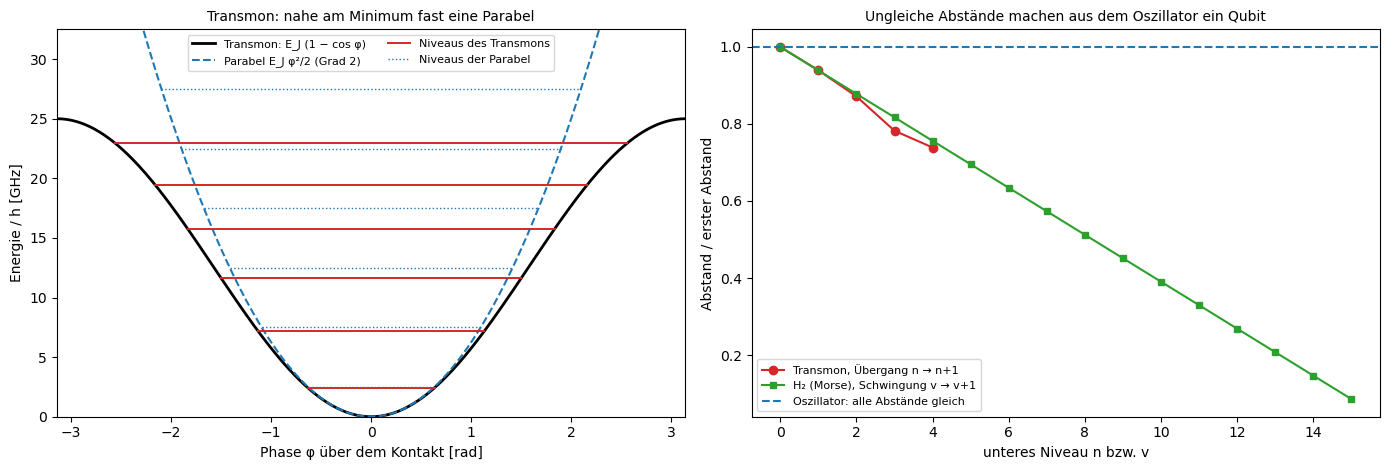

In [2]:
E_J, E_C = 12.5, 0.25         # Josephson- und Ladeenergie des Transmons [GHz], typische Werte
transmon_levels, h2_levels = oscillator.plot_spectra(E_J, E_C)

**2. Ein Rezept, vier Algebren: die Tensoralgebra und der Grad**

Der Code rechnet wörtlich in $T(V)/I$: Elemente sind Summen von Wörtern, und die Regel des Ideals wird so lange angewandt, bis jedes Wort geordnet ist (`tensoralgebra.Algebra`). Zwei Schalter, das Vorzeichen $s$ und die Form $B$, ergeben die vier Algebren der Einführung. Dann wird gezählt: Wie viele linear unabhängige Elemente entstehen aus gegebenen Erzeugern, wenn man immer wieder Kommutatoren bildet? Links für Bosonen mit einer Mode in der Weyl-Algebra, rechts für Fermionen mit $n$ Moden, also $2n$ Majorana-Operatoren, in der Clifford-Algebra (`tensoralgebra.plot_algebras`). Zum Zählen dienen geschlossene Formen derselben Regel; sie werden zuerst gegen die Ersetzungsregel geprüft.

**Begriffe**
- **Ideal:** eine Menge von Elementen, die man gleich null setzt, zusammen mit allem, was durch Multiplizieren von links und rechts daraus entsteht.
- **Abschluss einer Lie-Algebra:** Führt der Kommutator nicht aus einem endlichen Raum heraus, erzeugen die Gatter $e^{-i\theta G}$ eine Gruppe mit wenigen Parametern, die ein klassischer Rechner verfolgen kann.
- **Majorana-Operatoren $\gamma_i$:** Hälften eines Fermions, $c = (\gamma_1 + i\gamma_2)/2$. Produkte aus zweien beschreiben Hüpfen und Paarbildung (Grad 2), Produkte aus vieren eine Wechselwirkung (Grad 4).

Die erste Ausgabe zeigt dasselbe Wort in den vier Algebren: $(q + p)^2$ ist klassisch $q^2 + 2qp + p^2$, in der Weyl-Algebra kommt $-i$ dazu, in der äußeren Algebra ist es null und in der Clifford-Algebra die Zahl 2 (ein Vektor quadriert sich zu seiner Länge). Die geschlossenen Formen stimmen mit der Ersetzungsregel exakt überein. Unter 527 zufälligen Paaren von Weyl-Monomen mit Kommutator ungleich null hat der Kommutator 524-mal genau den Grad $a + b - 2$ und dreimal $a + b - 4$ (dort verschwindet der führende Term); bei geraden Clifford-Monomen sinkt der Grad um 2, 6 oder 10, nie um weniger als 2. Links: $\{q, p\}$ schließt mit 3 Elementen ($q$, $p$ und die Eins, die Heisenberg-Algebra), $\{q^2, p^2\}$ ebenfalls mit 3 ($\mathfrak{sp}(2)$), alle Elemente bis Grad 2 zusammen mit 6. Mit $q^3$ wächst die Dimension dagegen von Tiefe zu Tiefe, 3, 5, 7, 12, 28, 66, und der höchste Grad steigt auf 13. Rechts die Fermionen: Die Produkte aus zwei Majoranas erzeugen genau $\mathfrak{so}(2n)$, 15 Elemente für $n = 3$ und 91 für $n = 7$, wachsend wie $n^2$. Kommt ein einziger Term vom Grad 4 dazu, entstehen alle geraden Monome außer der Eins und dem Produkt aller Majoranas: 30 für $n = 3$ und 8190 für $n = 7$, wachsend wie $2^{2n}$. So groß ist der Raum, den ein klassischer Rechner dann verfolgen müsste.

Dasselbe Wort in vier Quotienten von T(V) (zwei Erzeuger):
  Sym(V), klassisch      (q + p)² = q² + 2·qp + p²            pq = qp
  Weyl, Bosonen          (q + p)² = q² + 2·qp + p² − i        pq = qp − i
  Λ(V), Formen           (a + b)² = 0                         ba = −ab
  Clifford, Fermionen    (a + b)² = 2                         ba = −ab
Geschlossene Formen gegen die Ersetzungsregel: größte Abweichung 0e+00
  Weyl: 527 Paare mit Kommutator ≠ 0; Grad des Kommutators minus (Grad A + Grad B): -2 in 524, -4 in 3
  Clifford: 74 Paare mit Kommutator ≠ 0; Grad des Kommutators minus (Grad A + Grad B): -2 in 31, -6 in 37, -10 in 6


Bosonen, eine Mode: Dimension der erzeugten Lie-Algebra je Tiefe der verschachtelten Kommutatoren (höchster Grad)
  {q, p}              : 2 (1), 3 (1), 3 (1), 3 (1), 3 (1), 3 (1)
  {q², p²}            : 2 (2), 3 (2), 3 (2), 3 (2), 3 (2), 3 (2)
  {q², p², qp, q, p}  : 5 (2), 6 (2), 6 (2), 6 (2), 6 (2), 6 (2)
  {q², p², q³}        : 3 (3), 5 (3), 7 (4), 12 (5), 28 (8), 66 (13)


Fermionen, n Moden (2n Majoranas): Grad 2 allein | Grad 2 und ein Term γ0γ1γ2γ3 vom Grad 4
  n = 3:    15 (so(6) hat 15) |    30 (gerade Monome ohne 1 und Parität: 30)
  n = 4:    28 (so(8) hat 28) |   126 (gerade Monome ohne 1 und Parität: 126)
  n = 5:    45 (so(10) hat 45) |   510 (gerade Monome ohne 1 und Parität: 510)
  n = 6:    66 (so(12) hat 66) |  2046 (gerade Monome ohne 1 und Parität: 2046)
  n = 7:    91 (so(14) hat 91) |  8190 (gerade Monome ohne 1 und Parität: 8190)


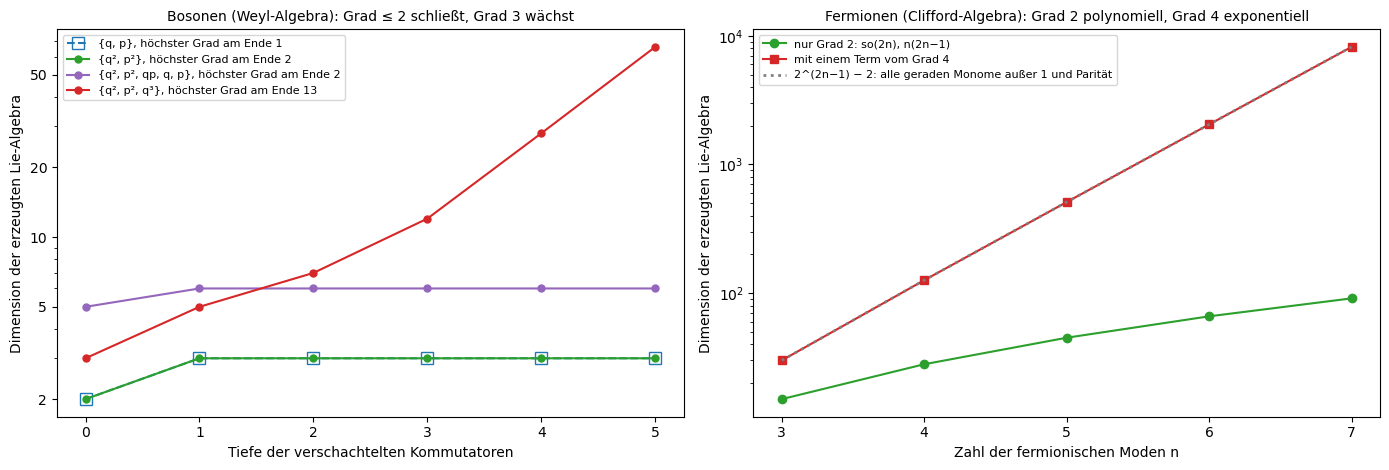

In [3]:
DEPTH = 5                     # Tiefe der verschachtelten Kommutatoren (Bosonen)
MODES = (3, 4, 5, 6, 7)       # Zahl der fermionischen Moden
bosons, fermions = tensoralgebra.plot_algebras(DEPTH, MODES)

**3. Vom Kommutator zur Phase: Heisenberg-Weyl im Endlichen**

Die Gleichung $[\hat q, \hat p] = i\hbar$ hat keine Lösung in endlichen Matrizen: Die Spur eines Kommutators ist null, die Spur von $i\hbar\,\mathbb{1}$ nicht. Die Ausgabe prüft zuerst, was stattdessen gilt, an einem Qudit mit $d = 5$: Clock $Z$, Shift $X$, die Weyl-Operatoren $D(q, p) = \tau^{qp}X^qZ^p$ und die Phase, die beim Multiplizieren entsteht (`weyl.checks`). Das Bild zeigt links, was eine Viertelperiode des Oszillators mit einem Wellenpaket macht, und rechts, wo das Endliche die Spur zurückzahlt: auf Gittern mit $d$ Punkten, auf denen $P = F^\dagger QF$ ist, und im Oszillator, der nach $N$ Zuständen abgeschnitten wird (`oscillator.plot_phase`).

**Begriffe**
- **Weyl-Relation:** $ZX = \zeta XZ$ mit $\zeta = e^{2\pi i/d}$, die potenzierte Form der Vertauschungsregel. Sie verlangt nur $\det(ZXZ^{-1}X^{-1}) = \zeta^d = 1$ und ist deshalb in $d \times d$-Matrizen erfüllbar.
- **Symplektisches Produkt:** $\omega(a, b) = qp' - q'p$ für $a = (q, p)$ und $b = (q', p')$. Es bestimmt die Phase in $D(a)D(b) = \tau^{-\omega(a, b)}D(a + b)$; mit $\tau = \zeta^{(d+1)/2}$ ist $\tau^2 = \zeta$, und $D$ wiederholt sich nach $d$ Schritten.
- **Clifford-Gatter:** Sie bilden Weyl-Operatoren auf Weyl-Operatoren ab, $UD(a)U^\dagger \propto D(Ma)$, mit einer Matrix $M$ der Determinante 1 (mod $d$), die $\omega$ erhält.

Die Ausgabe bestätigt für $d = 5$: $ZX = \zeta XZ$ gilt, und $\det(ZXZ^{-1}X^{-1}) = 1$, wie es sein muss. Die Phase beim Multiplizieren ist für alle 625 Paare $\tau^{-\omega(a, b)}$. Mit $\tau = e^{i\pi/d}$ gilt das auch, aber dann ist $D(q + d, p) \neq D(q, p)$; erst $\tau = \zeta^{(d+1)/2}$ macht $D$ periodisch. Die 25 Weyl-Operatoren sind eine Orthonormalbasis aller $5 \times 5$-Matrizen. Die Fourier-Transformation bildet die Gitterpunkte $(q, p)$ auf $(-p, q)$ ab (in der Ausgabe steht 4 für −1 mod 5): eine Vierteldrehung, nach vier Schritten wieder am Anfang. Das Phasengatter schert, $p \to p + q$, und beide zusammen erzeugen alle 120 Matrizen von $SL(2, \mathbb{Z}_5)$; das ist die Clifford-Gruppe eines Qudits, wenn man die Pauli-Operatoren herausteilt. Links dasselbe kontinuierlich: Nach einer Viertelperiode ist das Wellenpaket bis auf $3\cdot10^{-13}$ seine eigene Fourier-Transformierte, bis auf eine Phase von −45°. Rechts das Spur-Argument: Im nach 12 Zuständen abgeschnittenen Oszillator ist die Diagonale von $[Q, P]/i$ elfmal 1 und im letzten Niveau −11. Auf den Gittern gilt $[Q, P] = i$ für die untersten 56 % der Zustände ($d = 25$) bis 71 % ($d = 201$) auf 1 % genau; die laufende Summe steigt wie bei Heisenberg und fällt im oberen Viertel auf null zurück. Mit wachsendem $d$ wird der gute Teil größer: So wird die Weyl-Relation für $d \to \infty$ wieder zur Vertauschungsregel.

Qudit mit d = 5: ZX = ζXZ True; det(ZXZ⁻¹X⁻¹) = 1.000000 = det(ζ·1) = ζ^d = 1
  τ = ζ^((d+1)/2): D(a)D(b) = τ^(−ω(a,b)) D(a+b) für alle 625 Paare: True; D(q+d, p) = D(q, p): True
  τ = e^(iπ/d): D(a)D(b) = τ^(−ω(a,b)) D(a+b) für alle 625 Paare: True; D(q+d, p) = D(q, p): False
  Tr(D(a)† D(b))/d = δ_ab: True (25 Operatoren, Basis aller 5×5-Matrizen); Gruppenkommutator D(a)D(b)D(a)†D(b)† = ζ^(−ω(a,b))·1: True
  Fourier F: (q, p) → M·(q, p) mit M = [[0, 4], [1, 0]] (det 1, M⁴ = 1: True): eine Vierteldrehung des Gitters
  Phasengatter S: M = [[1, 0], [1, 1]] (det 1): eine Scherung p → p + q
  F und S erzeugen 120 symplektische Matrizen; |SL(2, Z_5)| = d(d²−1) = 120


Vierteldrehung t = π/2 (Periode 2π): größte Abweichung |ψ(t) − e^(iθ) ψ̃| = 2.6e-13, globale Phase θ = -45.0° (Fock-Rest -1e-14)
Abgeschnitten nach N = 12 Fock-Zuständen: Diagonale von [Q, P]/i = 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, -11; Spur -1.77636e-15
  Gitter mit d = 25: ⟨n|[Q,P]|n⟩/i auf 1 % genau für die untersten 14 Zustände (56%), laufende Summe höchstens 16.7, am Ende -6e-14
  Gitter mit d = 51: ⟨n|[Q,P]|n⟩/i auf 1 % genau für die untersten 32 Zustände (63%), laufende Summe höchstens 35.9, am Ende -5e-13
  Gitter mit d = 101: ⟨n|[Q,P]|n⟩/i auf 1 % genau für die untersten 68 Zustände (67%), laufende Summe höchstens 73.3, am Ende -6e-13
  Gitter mit d = 201: ⟨n|[Q,P]|n⟩/i auf 1 % genau für die untersten 142 Zustände (71%), laufende Summe höchstens 149.8, am Ende -8e-13


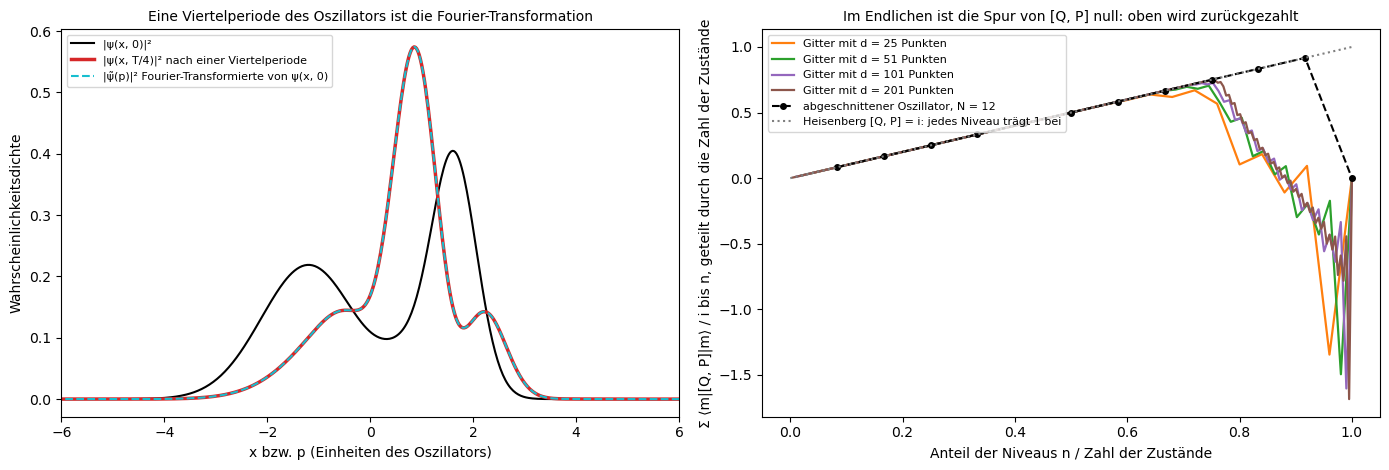

In [4]:
QUDIT = 5                     # ungerade Dimension des Qudits
GRIDS = (25, 51, 101, 201)    # Gitter mit d Punkten für Q und P
M_fourier, M_phase = weyl.checks(QUDIT)
ccr = oscillator.plot_phase(ds=GRIDS)

**4. Die Leiter im Phasenraum: Wigner-Funktionen vom Grad 1 bis 4**

Die Wigner-Funktion $W(x, p)$ stellt einen Zustand als Verteilung in der Phasenebene dar. Integriert über $p$ gibt sie die Verteilung in $x$ und umgekehrt, aber sie darf negativ werden. Oben entstehen aus dem Grundzustand vier Zustände, jeder mit einem Erzeuger höheren Grades: Verschiebung (Grad 1), Quetschung (Grad 2), kubische Phase $e^{i\gamma\hat x^3}$ (Grad 3) und die Kerr-Wechselwirkung $e^{-i\chi t\hat n^2}$ (Grad 4), die aus einem kohärenten Zustand eine Katze macht. Unten dasselbe für ein Qutrit ($d = 3$) mit der diskreten Wigner-Funktion, gebaut aus den Weyl-Operatoren von Schritt 3 (`phasespace.plot_wigner`).

**Begriffe**
- **Negativität $\delta$:** $\int |W| - 1$, das doppelte Volumen der negativen Bereiche; null für jede echte Wahrscheinlichkeitsverteilung.
- **Satz von Hudson (1974):** Ein reiner Zustand hat genau dann $W \geq 0$, wenn er gaußsch ist. Gross (2006) bewies das diskrete Gegenstück: Für ungerades $d$ sind es genau die Stabilisatorzustände.
- **Mana:** $\ln\sum|W|$, die Negativität eines Qudit-Zustands als Ressource (Veitch und andere 2014). Clifford-Gatter verschieben nur die Punkte des Gitters und ändern sie nicht; ein Quantenvorteil braucht deshalb Zustände oder Gatter mit Mana, etwa T-Gatter.

Oben: Der kohärente und der gequetschte Zustand haben überall $W \geq 0$ ($\delta = 0.000$); sie unterscheiden sich nur in der Form, ein Kreis und eine Ellipse mit derselben Fläche. Das ist der Satz von Hudson. Die kubische Phase biegt die Verteilung zu einer Banane mit blauen Streifen ($\delta = 0.332$, kleinster Wert −0.083), und die Kerr-Wechselwirkung teilt den kohärenten Zustand in zwei Hälften mit Interferenzstreifen dazwischen ($\delta = 0.608$, kleinster Wert −0.296): eine Katze. Unten das Qutrit: Alle 12 Stabilisatorzustände haben $W \geq 0$ und Mana 0. Sie sind Linien im $3 \times 3$-Gitter, $|0\rangle$ eine senkrechte und $F|0\rangle$ eine waagrechte, gedreht durch die Vierteldrehung aus Schritt 3. Der T-Zustand hat drei negative Felder (−0.10) und Mana 0.461, der strange state ein einziges mit $-1/3$ und Mana $0.511 = \ln(5/3)$. Unter 2000 zufälligen reinen Zuständen hat jeder ein negatives Feld: Ein Zustand mit positiver Wigner-Funktion ist die Ausnahme, und genau diese Ausnahme kann ein klassischer Rechner effizient simulieren.

Kontinuierlich: Normierung ∫W, Negativität δ = ∫|W| − 1, kleinster Wert von W
  Grad 1: kohärent (verschobenes |0⟩)     : ∫W = 1.0000, δ = 0.0000, min W = +0.000
  Grad 2: gequetscht, r = 0.8             : ∫W = 1.0000, δ = 0.0000, min W = +0.000
  Grad 3: kubische Phase, γ = 0.15        : ∫W = 0.9997, δ = 0.3324, min W = -0.083
  Grad 4: Kerr, e^(−iπn²/2)|α⟩ (Katze)    : ∫W = 1.0000, δ = 0.6083, min W = -0.296
Qutrit (d = 3): alle 12 Stabilisatorzustände haben W ≥ 0 (kleinster Wert -3.9e-16), Mana 0
  Stabilisator |0⟩                        : min W = +0.000, Mana = ln Σ|W| = 0.000
  Stabilisator F|0⟩                       : min W = +0.000, Mana = ln Σ|W| = 0.000
  T-Zustand T F|0⟩, T = diag(1, ζ₉, ζ₉⁻¹) : min W = -0.098, Mana = ln Σ|W| = 0.461
  strange state (|1⟩ − |2⟩)/√2            : min W = -0.333, Mana = ln Σ|W| = 0.511


  2000 zufällige reine Zustände: 100.0% mit negativem W, im Mittel min W = -0.182


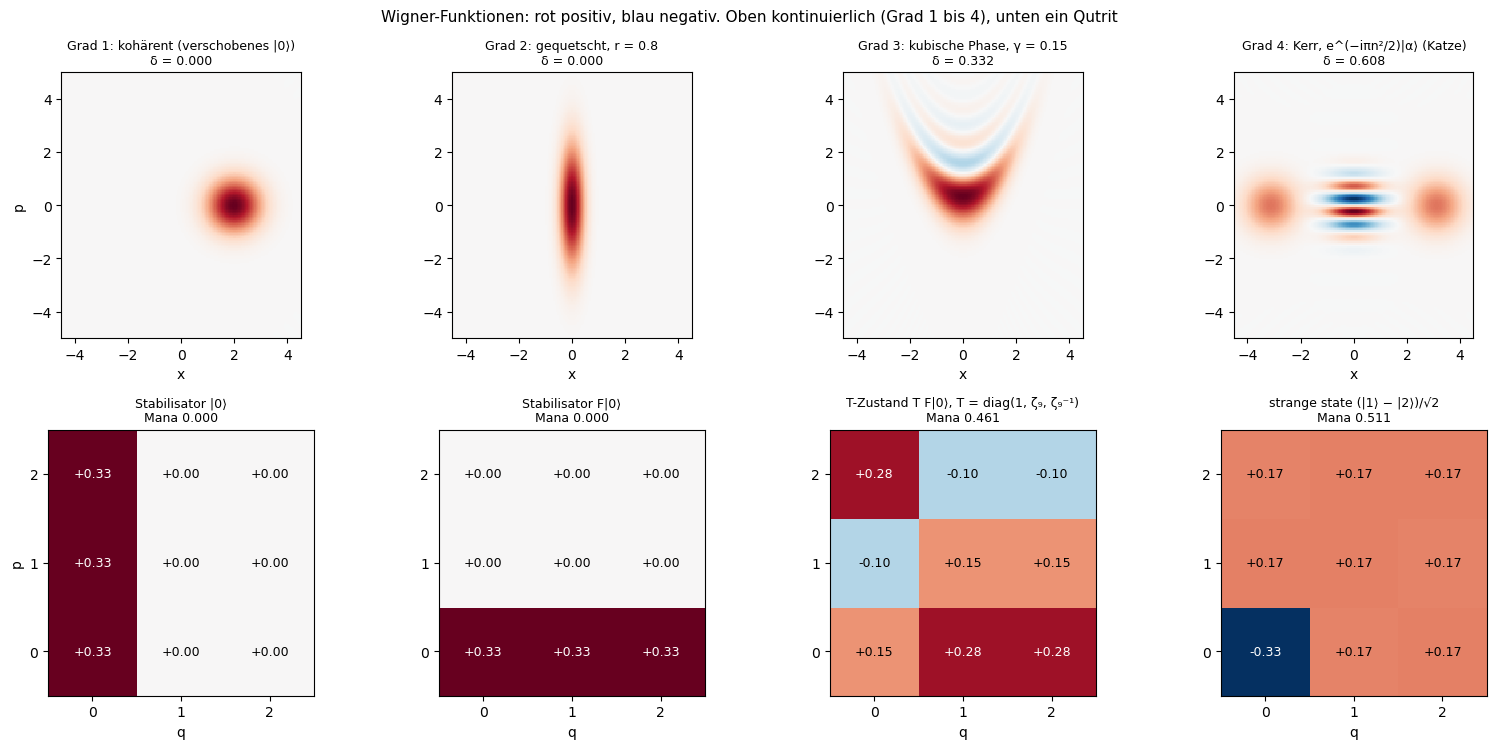

In [5]:
SQUEEZE, GAMMA, ALPHA = 0.8, 0.15, 2.2   # Quetschung r, kubische Phase γ, Amplitude α vor der Kerr-Entwicklung
wigner_cont, wigner_qutrit = phasespace.plot_wigner(r=SQUEEZE, gamma=GAMMA, alpha=ALPHA)

**5. Klassische Bahn oder Wellenpaket: wann ein klassisches Modell genügt**

Molekulardynamik rechnet Atome als Kugeln an Federn mit Newtons Gesetz. Wann ist das richtig? Nach Ehrenfest gehorcht der Mittelwert eines Wellenpakets $\frac{d}{dt}\langle\hat p\rangle = -\langle V'(\hat x)\rangle$, die klassische Bahn dagegen $-V'(\langle\hat x\rangle)$. Beides ist nur dann gleich, wenn $V'$ linear ist, also $V$ vom Grad 2. Gerechnet wird die Schwingung von H₂, nachdem die Bindung um 0.25 Å gestreckt wurde: quantenmechanisch exakt auf einem Gitter und klassisch, einmal mit der Parabel und einmal mit dem Morse-Potential aus Schritt 1 (`oscillator.plot_ehrenfest`).

**Begriffe**
- **Ehrenfest-Theorem:** Mittelwerte gehorchen $\frac{d}{dt}\langle\hat x\rangle = \langle\hat p\rangle/\mu$ und $\frac{d}{dt}\langle\hat p\rangle = -\langle V'(\hat x)\rangle$.
- **Wiederkehr (Revival):** Die Niveaus eines anharmonischen Oszillators liegen fast gleich weit auseinander. Ihre Phasen laufen deshalb langsam auseinander und treffen sich nach $T_{\mathrm{rev}} = 2\pi\hbar/(2\omega_ex_e)$ wieder.

Links: Im harmonischen Potential weicht der Mittelwert des Wellenpakets höchstens um $5\cdot10^{-12}$ Å von der klassischen Bahn ab, also nur um Rundungsfehler, über 160 fs und 21 Schwingungen (Periode 7.58 fs). Rechts: Im Morse-Potential schwingt $\langle x\rangle$ am Anfang mit 0.356 Å, bei 66 fs nur noch mit 0.061 Å: Das Paket hat sich über die ganze Bahn verteilt, obwohl seine Energie gleich geblieben ist. Bei 132 fs, der vorhergesagten Wiederkehr $2\pi\hbar/(2\omega_ex_e)$, ist die Schwingungsweite wieder 0.355 Å. Die klassische Bahn kennt nichts davon; sie schwingt immer mit 0.418 Å und mit ihrer eigenen, etwas längeren Periode. Solche Wiederkehr misst man mit kurzen Laserpulsen an Molekülen. Für die Chemie heißt das: Molekulardynamik mit klassischen Kräften ist für kleine Schwingungen gut und versagt dort, wo die Anharmonizität zählt, bei großen Auslenkungen, beim Brechen von Bindungen und bei leichten Atomen wie Wasserstoff.

H₂, Wellenpaket um 0.25 Å gestreckt, Schwingungsperiode 7.58 fs:
  harmonisch: größte Abweichung zwischen ⟨x⟩ und klassischer Bahn 5.1e-12 Å (Ehrenfest exakt für Grad 2)
  Morse: Schwingungsweite von ⟨x⟩ am Anfang 0.356 Å, um t = 66 fs 0.061 Å, um t = 132 fs (Wiederkehr 2π/(2ω_e x_e)) 0.355 Å; klassisch bleibt sie 0.418 Å


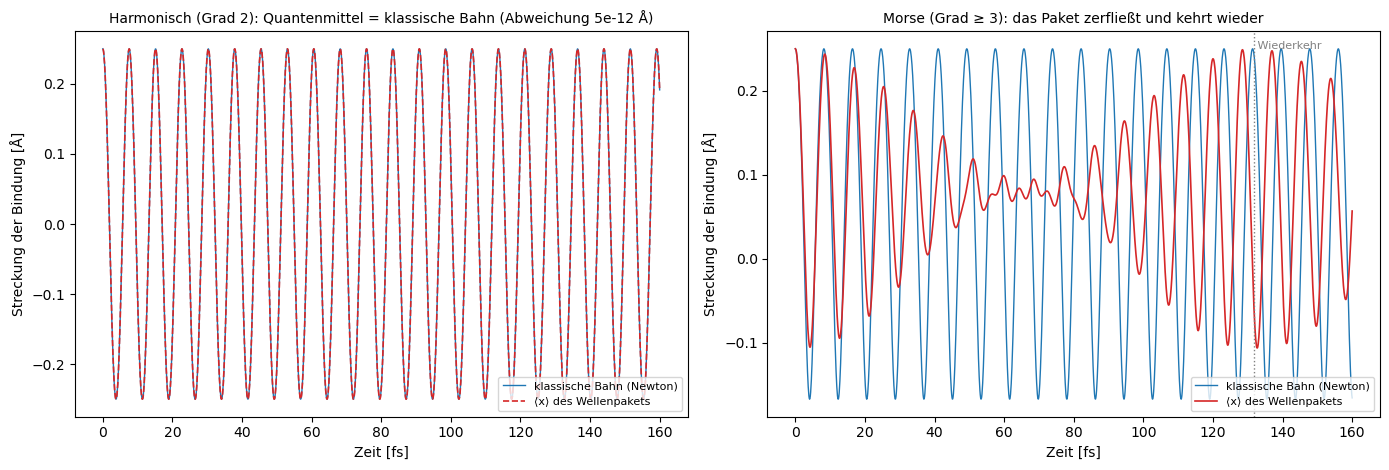

In [6]:
STRETCH = 0.25                # Streckung der Bindung von H₂ am Anfang [Å]
T_MAX = 160                   # Dauer [fs]
t_fs, paths = oscillator.plot_ehrenfest(STRETCH, T_MAX)

**6. Was ein klassischer Rechner schafft: Clifford+T und Hubbard**

Links Qubits: Eine Messgröße $Z$ wird rückwärts durch eine Schaltung aus 60 Lagen zufälliger Clifford-Gatter geschoben (Heisenberg-Bild). Ein Clifford-Gatter macht aus einem Pauli-String wieder genau einen, ein T-Gatter macht aus $X$ oder $Y$ zwei, $T^\dagger XT = (X - Y)/\sqrt2$. Gezählt werden die Pauli-Strings gegen die Zahl der T-Gatter (`simulability.heisenberg`, vorher gegen einen Zustandsvektor geprüft). Rechts Fermionen auf einer Kette, die mit Teilchen auf jedem zweiten Platz startet: Hüpfen allein (Grad 2) wird mit der $L \times L$-Matrix der Korrelationen gerechnet, mit der Hubbard-Wechselwirkung $U\,n_\uparrow n_\downarrow$ (Grad 4) exakt im ganzen Zustandsraum (`simulability.plot_simulability`).

**Begriffe**
- **Clifford-Hierarchie:** Pauli-Operatoren bilden die erste Stufe, Clifford-Gatter die zweite (sie bilden Paulis auf Paulis ab), das T-Gatter liegt in der dritten (es bildet Paulis auf Clifford-Gatter ab).
- **Gottesman–Knill:** Clifford-Schaltungen auf $n$ Qubits lassen sich in polynomieller Zeit simulieren; der Tableau-Simulator dazu steht in Schritt 3 von `symmetries`.
- **Imbalance:** Anteil der Teilchen auf geraden minus ungeraden Plätzen; am Anfang 1, im Gleichgewicht 0.

Die Prüfung vergleicht 240 Erwartungswerte aus kleinen Schaltungen mit dem vollen Zustandsvektor; die größte Abweichung ist $5\cdot10^{-15}$. Links: Ohne T-Gatter bleibt die Messgröße ein einziger Pauli-String, gleich wie viele Clifford-Gatter sie durchläuft (hier 2849), und die Rechnung dauert 15 ms. Ein T-Gatter auf einem Qubit, auf dem ein String $X$ oder $Y$ trägt, macht aus ihm zwei. Im Mittel über 6 zufällige Schaltungen wächst die Zahl der Strings um den Faktor 1.32 je T-Gatter, auf 71 206 bei 36 T-Gattern (420 ms). Der Faktor liegt unter 2, weil ein T-Gatter auf $I$ oder $Z$ nichts verzweigt und weil sich Strings wieder treffen. Die Kosten hängen also exponentiell von der Zahl der T-Gatter ab und nicht von den $2^{24} = 1.7\cdot10^7$ Amplituden eines Zustandsvektors. Rechts: Freie Fermionen auf 1024 Plätzen rechnet die $L \times L$-Matrix in 2.3 s. Mit $U = 4$ hat der Zustandsraum schon bei 12 Plätzen 853 776 Dimensionen, die Rechnung dauert 23 s; die zwei Plätze von 10 auf 12 haben die Dimension um das 13-Fache und die Rechenzeit um das 20-Fache vergrößert. Bei $U = 0$ stimmen beide Rechnungen auf $8\cdot10^{-15}$ überein. Die Wechselwirkung ändert auch die Physik: Ohne sie ist die Imbalance bei $t = 10$ noch −0.137, mit $U = 4$ fast null (−0.002).

Prüfung: 240 Erwartungswerte ⟨Z_q⟩ aus 40 Schaltungen mit 6 Qubits und 6 T-Gattern (33 davon ≠ 0), Pauli-Pfade gegen Zustandsvektor: größte Abweichung 5e-15


24 Qubits, Messgröße Z auf Qubit 12, 60 Lagen Clifford-Gatter (2849 Gatter); ein Zustandsvektor bräuchte 2^24 = 1.7e+07 Amplituden. Mittel über 6 Schaltungen je Zahl der T-Gatter:
  T-Gatter | Pauli-Strings (höchstens gleichzeitig) | Rechenzeit
         0 |          1 |     14.7 ms
         4 |          5 |     14.9 ms
         8 |         19 |     16.6 ms
        12 |         55 |     15.1 ms
        16 |        515 |     16.4 ms
        20 |       1231 |     22.7 ms
        24 |       1182 |     17.6 ms
        28 |      11836 |     50.8 ms
        32 |      20356 |    112.2 ms
        36 |      71206 |    419.8 ms
  Anstieg in der zweiten Hälfte: Faktor 2^0.40 = 1.32 je T-Gatter
Fermionen, L = 8: Hubbard mit U = 0 gegen freie Rechnung, größte Abweichung der Imbalance 7.7e-15


  frei (L×L-Matrix): L = 4: 0 ms, L = 8: 0 ms, L = 16: 0 ms, L = 32: 1 ms, L = 64: 2 ms, L = 128: 9 ms, L = 256: 61 ms, L = 512: 380 ms, L = 1024: 2259 ms
  Hubbard U = 4 (Dimension C(L, L/2)²): L = 4: 36 Zustände  0.02 s, L = 6: 400 Zustände  0.02 s, L = 8: 4 900 Zustände  0.13 s, L = 10: 63 504 Zustände  1.18 s, L = 12: 853 776 Zustände  23.00 s
  Imbalance bei t = 10, L = 12: frei -0.137, mit U = 4 -0.002


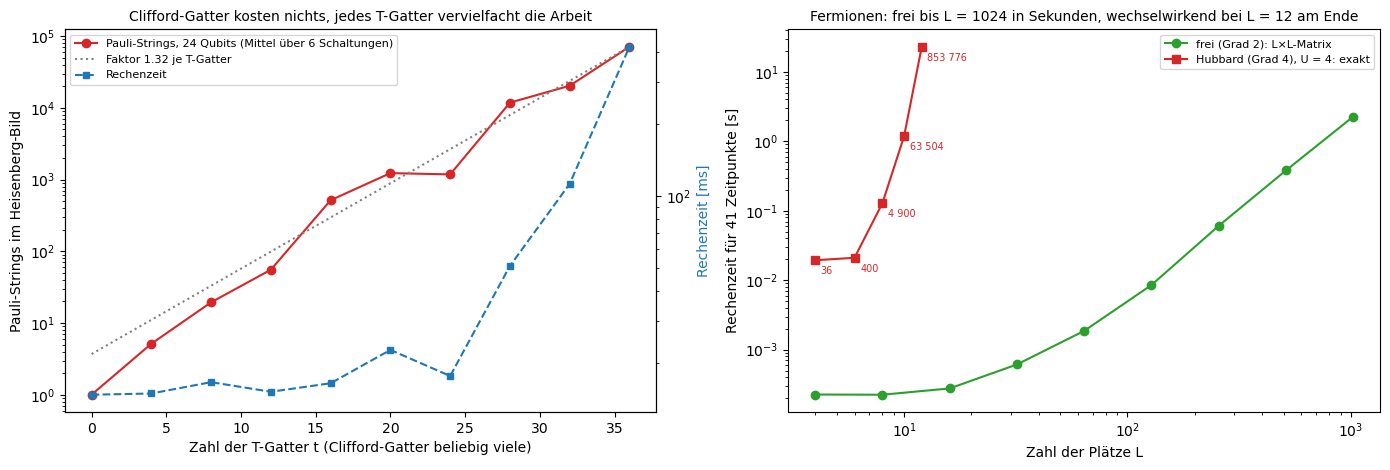

In [7]:
QUBITS, LAYERS = 24, 60                  # Schaltung für die Pauli-Pfade
T_GATES = range(0, 37, 4)                # Zahl der T-Gatter
SITES_HUBBARD = (4, 6, 8, 10, 12)        # Kettenlängen mit Wechselwirkung (L = 12: 853 776 Zustände, etwa 25 s)
strings, t_free, t_hubbard = simulability.plot_simulability(QUBITS, LAYERS, T_GATES, L_hub=SITES_HUBBARD)

**7. Ausblick: Quantensimulation einordnen und offene Systeme**

Jedes Simulationsverfahren lässt sich mit drei Fragen einordnen: klassisches oder quantenmechanisches Modell, klassische oder Quanten-Hardware, Grundzustand oder Zeitentwicklung. Die Grad-Leiter sagt, wann die billige Antwort genügt. Ein klassisches Modell ist exakt, solange die Kräfte linear sind (Schritt 5), und klassische Hardware genügt, solange die Erzeuger quadratisch sind oder nur wenige T-Gatter vorkommen (Schritt 6). Molekulardynamik mit Federn, Hartree–Fock (die beste einzelne Slater-Determinante, also ein Zustand freier Fermionen) und Gottesman–Knill sind deshalb dieselbe Idee in drei Gebieten. Die Verfahren für Quanten-Hardware stehen in den Prinzip-Notebooks: Trotter-Schritte und das Variationsprinzip mit VQE in `approximation`, die Ausbreitung von Operatoren (OTOC) und die Vielteilchen-Lokalisierung in `stability`.

Als Code wäre der nächste Schritt ein offenes System: ein Qubit mit Energieverlust ($T_1$) und Dephasierung ($T_2$), einmal mit der Lindblad-Gleichung $\dot\rho = -i[H, \rho] + \sum_k \gamma_k\big(L_k\rho L_k^\dagger - \tfrac12\{L_k^\dagger L_k, \rho\}\big)$ und einmal als Mittel vieler Quantentrajektorien, die zufällig springen. Beide müssen übereinstimmen, und die Trajektorien sind das, was eine heutige Hardware mit Messungen und Resets mitten in der Schaltung nachbilden kann.